<a href="https://colab.research.google.com/github/fabianmoore/MineriaDatos/blob/main/Actividad_2_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", module="jupyter_client")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [7]:
from google.colab import files
import pandas as pd

subido = files.upload()
df = pd.read_csv("Groceries_dataset.csv")
print(df.shape)
df.head()

Saving Groceries_dataset.csv to Groceries_dataset (2).csv
(38765, 3)


,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


In [8]:
!pip install -q mlxtend
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [9]:
print("Filas:", len(df))
print("Nulos:\n", df.isna().sum())
print("Duplicados exactos:", df.duplicated().sum())

df["itemDescription"] = df["itemDescription"].str.strip().str.lower()
df = df.dropna(subset=["Member_number", "Date", "itemDescription"]).drop_duplicates()

print("Ítems distintos:", df["itemDescription"].nunique())
print("Transacciones:", df.groupby(["Member_number", "Date"]).ngroups)

Filas: 38765
Nulos:
 Member_number      0
Date               0
itemDescription    0
dtype: int64
Duplicados exactos: 759
Ítems distintos: 167
Transacciones: 14963


2. Descripción y limpieza
- **Transacción:** lo que un socio compró en una fecha (`Member_number` + `Date`).
- **Ítem:** un producto (`itemDescription`).
- Hay **[N] transacciones** y **[N] ítems distintos**.
- Revisé nulos, duplicados y nombres inconsistentes, y pasé los productos a minúsculas sin espacios sobrantes.

In [10]:
transactions = (df.groupby(["Member_number", "Date"])["itemDescription"]
                  .apply(lambda s: list(set(s))).tolist())

te = TransactionEncoder()
basket = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print(basket.shape)
basket.head()

(14963, 167)


,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,beverages,bottled beer,...,uht-milk,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


Codificación one-hot:

Armé una fila por transacción y una columna por ítem con True/False. Apriori necesita este formato porque calcula el soporte contando en cuántas filas aparece cada combinación.

whole milk          0.157923
other vegetables    0.122101
rolls/buns          0.110005
soda                0.097106
yogurt              0.085879
root vegetables     0.069572
tropical fruit      0.067767
bottled water       0.060683
sausage             0.060349
citrus fruit        0.053131
pastry              0.051728
pip fruit           0.049054
shopping bags       0.047584
canned beer         0.046916
bottled beer        0.045312
dtype: float64


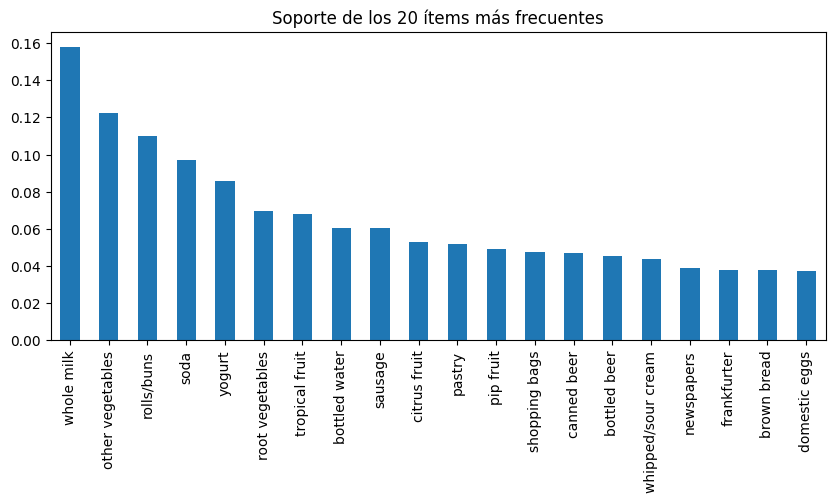

Ítems con soporte >= 1%: 64
Ítems con soporte >= 0.5%: 89


In [11]:
freq_items = basket.mean().sort_values(ascending=False)
print(freq_items.head(15))
freq_items.head(20).plot(kind="bar", figsize=(10, 4), title="Soporte de los 20 ítems más frecuentes")
plt.show()
print("Ítems con soporte >= 1%:", (freq_items >= 0.01).sum())
print("Ítems con soporte >= 0.5%:", (freq_items >= 0.005).sum())

Las compras son chicas (pocos ítems por boleta), así que los soportes son bajos y las confianzas también. Por eso un umbral de 70 %, como en la 2.5, aquí daría casi cero reglas.

In [12]:
def get_rules(freq, conf):
    try:
        return association_rules(freq, metric="confidence", min_threshold=conf)
    except TypeError:  # versiones de mlxtend que piden num_itemsets
        return association_rules(freq, num_itemsets=len(basket), metric="confidence", min_threshold=conf)

freq = apriori(basket, min_support=0.005, use_colnames=True)
rules = get_rules(freq, 0.10).sort_values("lift", ascending=False)

rules["antecedente"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
rules["consecuente"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
cols = ["antecedente", "consecuente", "support", "confidence", "lift"]
print(len(freq), "itemsets;", len(rules), "reglas")
rules[cols].head(15)

126 itemsets; 19 reglas


,antecedente,consecuente,support,confidence,lift
5,frankfurter,other vegetables,0.005146,0.136283,1.116150
0,bottled beer,whole milk,0.007151,0.157817,0.999330
14,sausage,whole milk,0.008955,0.148394,0.939663
7,newspapers,whole milk,0.005614,0.144330,0.913926
4,domestic eggs,whole milk,0.005280,0.142342,0.901341
6,frankfurter,whole milk,0.005280,0.139823,0.885388
11,pork,whole milk,0.005012,0.135135,0.855703
10,pip fruit,whole milk,0.006616,0.134877,0.854071
3,citrus fruit,whole milk,0.007151,0.134591,0.852259
15,shopping bags,whole milk,0.006349,0.133427,0.844887


Ordené por lift porque mide cuánto más frecuente es el consecuente cuando aparece el antecedente, comparado con su frecuencia normal. Un lift cercano a 1 significa que no hay asociación real.

In [13]:
configs = [(0.01, 0.10), (0.005, 0.10), (0.002, 0.20)]
filas = []
for s, c in configs:
    f = apriori(basket, min_support=s, use_colnames=True)
    r = get_rules(f, c) if len(f) > 0 else []
    filas.append({"soporte_min": s, "confianza_min": c, "itemsets": len(f), "reglas": len(r)})
pd.DataFrame(filas)

,soporte_min,confianza_min,itemsets,reglas
0,0.010,0.1,69,4
1,0.005,0.1,126,19
2,0.002,0.2,330,0


5. Comparación de umbrales
| Config. | Soporte | Confianza | Itemsets | Reglas |
|---|---|---|---|---|
| A | 1 % | 10 % | [N] | [N] |
| B | 0,5 % | 10 % | 126 | 19 |
| C | 0,2 % | 20 % | [N] | [N] |

**Conclusión:** al bajar el soporte aparecen más itemsets y reglas, pero muchas se apoyan en pocas compras. Elijo la configuración **[A/B/C]** porque equilibra cantidad de reglas y respaldo.

In [14]:
rules[cols].head(10)  # elige 5 valiosas y 1 para descartar

,antecedente,consecuente,support,confidence,lift
5,frankfurter,other vegetables,0.005146,0.136283,1.116150
0,bottled beer,whole milk,0.007151,0.157817,0.999330
14,sausage,whole milk,0.008955,0.148394,0.939663
7,newspapers,whole milk,0.005614,0.144330,0.913926
4,domestic eggs,whole milk,0.005280,0.142342,0.901341
6,frankfurter,whole milk,0.005280,0.139823,0.885388
11,pork,whole milk,0.005012,0.135135,0.855703
10,pip fruit,whole milk,0.006616,0.134877,0.854071
3,citrus fruit,whole milk,0.007151,0.134591,0.852259
15,shopping bags,whole milk,0.006349,0.133427,0.844887


In [15]:
# Verificación manual de una regla (cambia los nombres por los de tu regla elegida)
A, B = "yogurt", "whole milk"
n = len(basket)
cuenta_A = basket[A].sum()
cuenta_AB = (basket[A] & basket[B]).sum()
print("Soporte:", cuenta_AB, "/", n, "=", round(cuenta_AB / n, 4))
print("Confianza:", cuenta_AB, "/", cuenta_A, "=", round(cuenta_AB / cuenta_A, 4))

Soporte: 167 / 14963 = 0.0112
Confianza: 167 / 1285 = 0.13


Verificación manual:


Regla **[A] ⇒ [B]**: [conteo ambos]/[total] = soporte [%]; [conteo ambos]/[conteo A] = confianza [%]. Coincide con mlxtend, así que los datos están bien preparados.

7. Reflexión final:


En la 2.5 los umbrales de 25 % y 70 % funcionaban con 8 boletas, pero con miles de compras reales dejan casi sin reglas. Aprendí que la confianza sola engaña: muchas reglas hacia *whole milk* parecen buenas solo porque la leche es muy popular, y el lift permite separarlas de las asociaciones reales. Los umbrales hay que elegirlos mirando los datos y probando varias configuraciones.